## 1. Business Understanding

Ketika sebuah pesanan diperkirakan terlambat, tim layanan pelanggan dapat memprioritaskan pesanan itu untuk ditinjau. Dari transaksi Olist Brasil, kita ingin menjawab dua pertanyaan.

1. Bagaimana perbedaan skor ulasan antara pesanan yang tiba tepat waktu dan yang terlambat?
2. Setelah persetujuan pesanan, saat estimasi pengiriman dan tenggat penjual sudah tersedia, seberapa baik kita dapat mengenali pesanan yang akan terlambat?

Satu observasi mewakili satu pesanan. Pesanan dianggap terlambat jika tanggal tiba melewati tanggal yang dijanjikan. Untuk menilai model, kita gunakan F1 pada kelas terlambat serta periksa berapa banyak keterlambatan yang terdeteksi dan berapa banyak peringatan yang keliru.

## 2. Data Understanding

Jalankan notebook dari direktori proyek dengan folder `dataset/` di sebelahnya. Inventaris berikut merangkum sembilan tabel dari eksplorasi awal. Tabel pesanan menyediakan tanggal transaksi, tabel item memberi tenggat pengiriman penjual, dan tabel ulasan menyediakan skor dari pelanggan.

In [54]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

d = Path("dataset")
orders  = pd.read_csv(d / "olist_orders_dataset.csv")
reviews = pd.read_csv(d / "olist_order_reviews_dataset.csv")
items   = pd.read_csv(d / "olist_order_items_dataset.csv")

tables = {"orders": orders, "order_reviews": reviews, "order_items": items}
display(pd.DataFrame(
    {name: {"Baris": len(t), "Kolom": t.shape[1], "Duplikat": t.duplicated().sum(), "Kosong": t.isna().sum().sum()}
     for name, t in tables.items()}
).T)

display(pd.concat({n: t.isna().sum()[t.isna().any()].rename("Kosong") for n, t in tables.items()}).to_frame())

,Baris,Kolom,Duplikat,Kosong
orders,99441,8,0,4908
order_reviews,99224,7,0,145903
order_items,112650,7,0,0


Kosong
orders        order_approved_at                 160
              order_delivered_carrier_date     1783
              order_delivered_customer_date    2965
order_reviews review_comment_title            87656
              review_comment_message          58247

### Penanganan nilai kosong

Kolom yang digunakan dari masing-masing tabel:
- **orders**: `order_id`, `order_status` (filter), `order_purchase_timestamp`, `order_approved_at`, `order_delivered_customer_date`, `order_estimated_delivery_date`
- **order_reviews**: `order_id`, `review_score`
- **order_items**: `order_id`, `shipping_limit_date`

Dari kolom yang digunakan diatas yang memiliki nilai kosong adalah:
- `orders`: `order_approved_at` (160 baris) dan `order_delivered_customer_date` (2965 baris)
- `order_reviews`: `review_comment_title` dan `review_comment_message` tidak dipakai

Strategi yang digunakan adalah **drop baris** (bukan imputasi), karena tanggal tidak dapat diperkirakan secara bermakna. Baris dengan nilai kosong pada kolom tanggal yang dibutuhkan dibuang. Kolom komentar ulasan dibiarkan karena tidak digunakan.

In [55]:
needed_cols = ["order_purchase_timestamp", "order_delivered_customer_date",
               "order_estimated_delivery_date"]
before = len(orders)
orders_clean = orders.dropna(subset=needed_cols)
after = len(orders_clean)
display(pd.DataFrame({
    "Sebelum drop": [before],
    "Setelah drop": [after],
    "Baris dibuang": [before - after]
}, index=["orders"]))
print("Nilai kosong setelah drop:")
display(orders_clean[needed_cols].isna().sum().rename("Kosong").to_frame())

,Sebelum drop,Setelah drop,Baris dibuang
orders,99441,96476,2965


Nilai kosong setelah drop:


,Kosong
order_purchase_timestamp,0
order_delivered_customer_date,0
order_estimated_delivery_date,0


### Status pesanan

Distribusi status menunjukkan berapa banyak pesanan yang sudah terkirim dan dapat diperiksa tanggal tibanya.

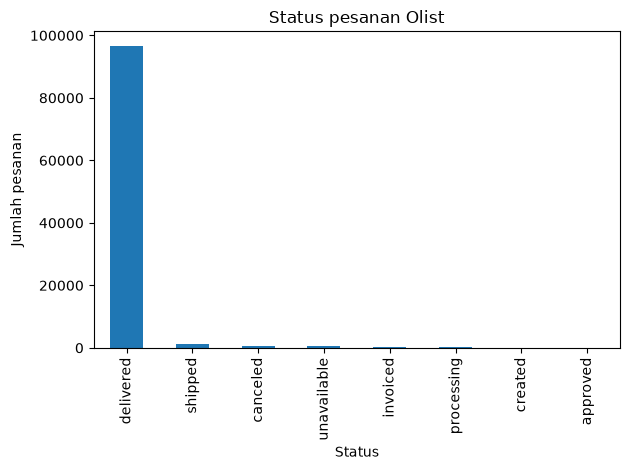

In [56]:
status_counts = orders["order_status"].value_counts()
status_counts.plot.bar(title="Status pesanan Olist", ylabel="Jumlah pesanan", xlabel="Status")
plt.tight_layout()
plt.show()

### Estimasi, waktu tiba, dan durasi keterlambatan

Untuk EDA, ambil pesanan berstatus *delivered* dengan tanggal pembelian, estimasi, dan penerimaan yang lengkap. Seluruh perbandingan tanggal tiba menggunakan hari kalender agar pesanan yang sampai pada tanggal janji tetap dihitung tepat waktu.

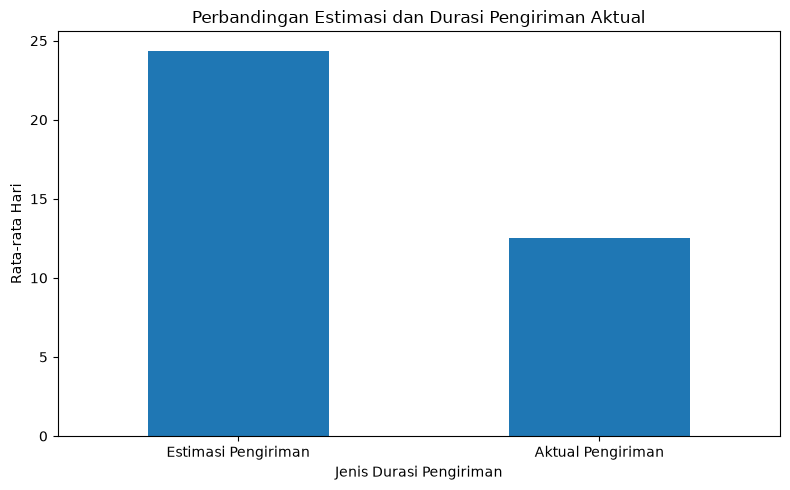

In [57]:
date_cols = ["order_purchase_timestamp", "order_approved_at",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

delivered = orders.loc[orders["order_status"].eq("delivered"), ["order_id", *date_cols]].copy()
data = delivered.dropna(subset=["order_purchase_timestamp", "order_delivered_customer_date",
                                "order_estimated_delivery_date"]).copy()
purchase = data["order_purchase_timestamp"].dt.normalize()
estimate = data["order_estimated_delivery_date"].dt.normalize()
arrival = data["order_delivered_customer_date"].dt.normalize()
data["estimasi_hari"] = (estimate - purchase).dt.days
data["aktual_hari"] = (arrival - purchase).dt.days
data["durasi_keterlambatan"] = (arrival - estimate).dt.days
data["is_late"] = data["durasi_keterlambatan"].gt(0).astype(int)

perbandingan = data[["estimasi_hari", "aktual_hari"]].mean()

perbandingan.plot(kind="bar", figsize=(8, 5))

plt.title("Perbandingan Estimasi dan Durasi Pengiriman Aktual")
plt.xlabel("Jenis Durasi Pengiriman")
plt.ylabel("Rata-rata Hari")
plt.xticks(
    ticks=[0, 1],
    labels=["Estimasi Pengiriman", "Aktual Pengiriman"],
    rotation=0
)
plt.tight_layout()
plt.show()

,Pesanan,Persentase (%)
Tepat waktu,89936,93.23
Terlambat,6534,6.77


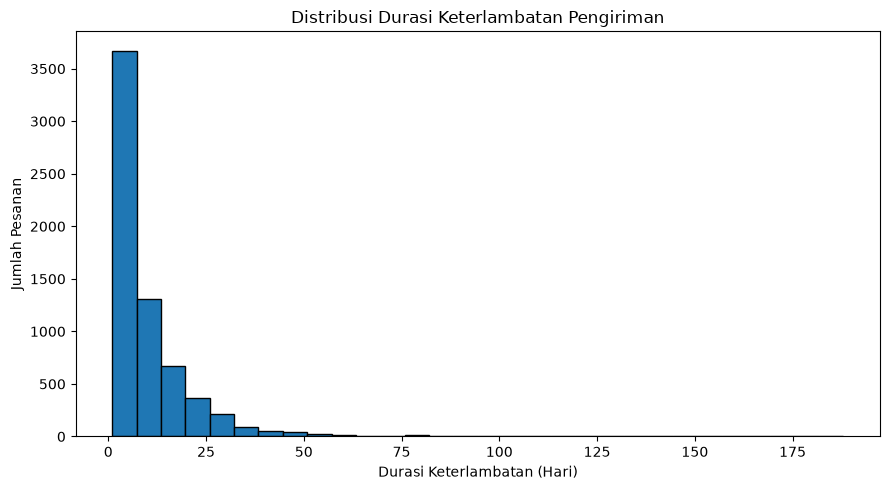

In [58]:
counts = data["is_late"].value_counts().reindex([0, 1], fill_value=0)
counts.index = ["Tepat waktu", "Terlambat"]
display(pd.DataFrame({"Pesanan": counts, "Persentase (%)": (100 * counts / counts.sum()).round(2)}))
terlambat = data.loc[data["is_late"].eq(1)]
plt.figure(figsize=(9, 5))

plt.hist(
    terlambat["durasi_keterlambatan"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribusi Durasi Keterlambatan Pengiriman")
plt.xlabel("Durasi Keterlambatan (Hari)")
plt.ylabel("Jumlah Pesanan")
plt.tight_layout()
plt.show()

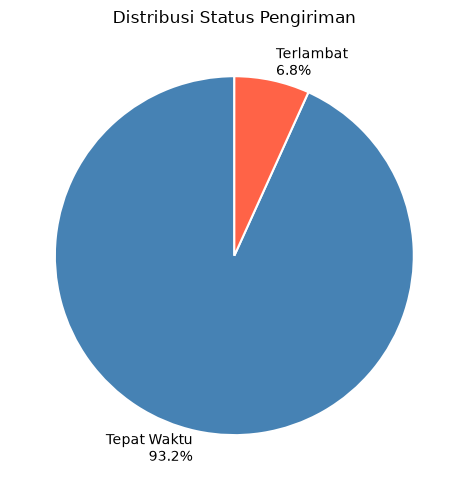

In [59]:
counts = data["is_late"].value_counts().reindex([0, 1], fill_value=0)
plt.figure(figsize=(5, 5))
plt.pie(
    counts,
    labels=[f'Tepat Waktu\n{counts[0]/counts.sum()*100:.1f}%',
             f'Terlambat\n{counts[1]/counts.sum()*100:.1f}%'],
    colors=["steelblue", "tomato"],
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5}
)
plt.title("Distribusi Status Pengiriman")
plt.tight_layout()
plt.show()

### Ulasan dan ketepatan pengiriman

Rata-ratakan skor dalam setiap pesanan sebelum membandingkan kelompok. Dengan cara ini, pesanan dengan beberapa ulasan tetap memiliki bobot yang sama dengan pesanan berulasan tunggal.

In [60]:
review_per_order = reviews.groupby("order_id")["review_score"].mean()
with_reviews = data.join(review_per_order, on="order_id", validate="one_to_one")
review_summary = with_reviews.groupby("is_late")["review_score"].agg(
    pesanan_dengan_ulasan="count", rata_rata="mean", median="median"
)
display(review_summary.rename(index={0: "Tepat waktu", 1: "Terlambat"}).round(2))

,pesanan_dengan_ulasan,rata_rata,median
is_late,,,
Tepat waktu,89443,4.29,5.0
Terlambat,6381,2.27,1.0


## 3. Data Preparation

Estimasi dan waktu tiba menentukan label. Untuk memprediksinya, kita gunakan tiga informasi yang tersedia sebelum paket tiba. Fitur tersebut adalah durasi dari pembelian hingga estimasi (hari penuh), waktu persetujuan (jam), dan durasi dari pembelian hingga tenggat pengiriman paling awal di antara item pesanan (hari penuh). Tanggal tiba aktual dan skor ulasan hanya digunakan untuk label dan analisis deskriptif.

Pesanan dengan waktu persetujuan atau tenggat yang kosong dikeluarkan dari populasi model. Pemeriksaan jumlah baris berikut menunjukkan perubahan cakupan dari EDA ke pelatihan.

In [61]:
items["shipping_limit_date"] = pd.to_datetime(items["shipping_limit_date"])
first_deadline = items.groupby("order_id")["shipping_limit_date"].min()
model_data = data.join(first_deadline, on="order_id", validate="one_to_one")
model_data = model_data.dropna(subset=["order_approved_at", "shipping_limit_date"]).copy()

checkout = model_data["order_purchase_timestamp"]
model_data["estimated_delivery_days"] = (model_data["order_estimated_delivery_date"] - checkout).dt.days
model_data["approval_time"] = (model_data["order_approved_at"] - checkout).dt.total_seconds() / 3600
model_data["seller_deadline_gap"] = (model_data["shipping_limit_date"] - checkout).dt.days

features = ["estimated_delivery_days", "approval_time", "seller_deadline_gap"]
X = model_data[features]
y = model_data["is_late"]
display(pd.Series({"Seluruh pesanan": len(orders), "Berstatus delivered": len(delivered),
                   "Tanggal EDA lengkap": len(data), "Fitur model lengkap": len(X)}, name="Pesanan"))
display(X.describe().round(2))

Seluruh pesanan        99441
Berstatus delivered    96478
Tanggal EDA lengkap    96470
Fitur model lengkap    96456
Name: Pesanan, dtype: int64

,estimated_delivery_days,approval_time,seller_deadline_gap
count,96456.00,96456.00,96456.00
mean,23.37,10.28,6.39
std,8.76,20.54,4.63
min,2.00,0.00,2.00
25%,18.00,0.22,5.00
50%,23.00,0.34,6.00
75%,28.00,14.52,7.00
max,155.00,741.44,1052.00


### Pemisahan data latih dan data uji

In [62]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## 4. Modeling

Model memprediksi status keterlambatan pesanan. Untuk setiap algoritma, Grid Search membandingkan enam kombinasi parameter melalui cross validation tiga fold pada data latih. Kriteria pemilihannya adalah rata-rata F1 kelas terlambat. Grid Search kemudian melatih ulang konfigurasi terpilih pada seluruh data latih.

### Random Forest

Random Forest menggabungkan prediksi banyak pohon untuk menangkap hubungan antara durasi persetujuan, estimasi pengiriman, dan tenggat penjual. Bobot kelas seimbang memberi pesanan terlambat pengaruh lebih besar saat pelatihan. Dengan jumlah pohon tetap 100, pencarian menguji kedalaman pohon dan jumlah minimum pesanan pada setiap daun untuk mengendalikan kompleksitas model.

In [63]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf_search = GridSearchCV(
    RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
    ),
    param_grid={
        "max_depth": [3, 5, 8],
        "min_samples_leaf": [5, 20],
    },
    scoring="f1",
    cv=3,
    n_jobs=2,
)
rf_search.fit(X_train, y_train)
rf_final = rf_search.best_estimator_

print("Parameter terpilih:", rf_search.best_params_)
print("F1 Late validasi:", round(rf_search.best_score_, 3))

Parameter terpilih: {'max_depth': 8, 'min_samples_leaf': 20}
F1 Late validasi: 0.155


### XGBoost

XGBoost menambahkan pohon secara bertahap untuk memperbaiki prediksi dari pohon sebelumnya. Rasio kelas pada data latih memberi bobot lebih besar pada kelas terlambat. Grid Search menguji kedalaman pohon dan laju pembelajaran untuk memilih seberapa rumit setiap pohon dan seberapa besar kontribusinya pada prediksi akhir.

In [64]:
from xgboost import XGBClassifier

# Rasio pesanan tepat waktu terhadap pesanan terlambat pada data latih.
scale = (y_train == 0).sum() / (y_train == 1).sum()

xgb_search = GridSearchCV(
    XGBClassifier(
        n_estimators=100,
        scale_pos_weight=scale,
        eval_metric="logloss",
        random_state=42,
        n_jobs=1,
    ),
    param_grid={
        "max_depth": [3, 5],
        "learning_rate": [0.05, 0.1, 0.3],
    },
    scoring="f1",
    cv=3,
    n_jobs=2,
)
xgb_search.fit(X_train, y_train)
xgb_final = xgb_search.best_estimator_

print("Parameter terpilih:", xgb_search.best_params_)
print("F1 Late validasi:", round(xgb_search.best_score_, 3))

Parameter terpilih: {'learning_rate': 0.1, 'max_depth': 3}
F1 Late validasi: 0.156


## 5. Evaluation

Baseline memprediksi semua pesanan sebagai kelas terbanyak di data latih. Bandingkan F1 kelas terlambat dengan baseline tersebut. Precision mengukur proporsi peringatan yang benar, sedangkan recall mengukur bagian dari seluruh keterlambatan yang terdeteksi. Confusion matrix menunjukkan jumlah pesanan pada tiap jenis kesalahan.

In [65]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

final_models = {"Random Forest": rf_final, "XGBoost": xgb_final}
evaluation_models = {"Baseline": baseline, **final_models}

scores = {}
for split, features, target in [
    ("Train", X_train, y_train),
    ("Test", X_test, y_test),
]:
    rows = []
    for name, model in evaluation_models.items():
        pred = model.predict(features)
        rows.append({
            "Model": name,
            "F1 Late": f1_score(target, pred, zero_division=0),
            "Precision Late": precision_score(target, pred, zero_division=0),
            "Recall Late": recall_score(target, pred, zero_division=0),
            "Accuracy": accuracy_score(target, pred),
        })
    scores[split] = pd.DataFrame(rows).set_index("Model")

pd.concat(scores, axis=1).round(3)

Train                                        Test  \
              F1 Late Precision Late Recall Late Accuracy F1 Late   
Model                                                               
Baseline        0.000          0.000       0.000    0.932   0.000   
Random Forest   0.165          0.093       0.746    0.486   0.155   
XGBoost         0.159          0.090       0.699    0.498   0.155   

                                                   
              Precision Late Recall Late Accuracy  
Model                                              
Baseline               0.000       0.000    0.933  
Random Forest          0.087       0.703    0.487  
XGBoost                0.087       0.685    0.502

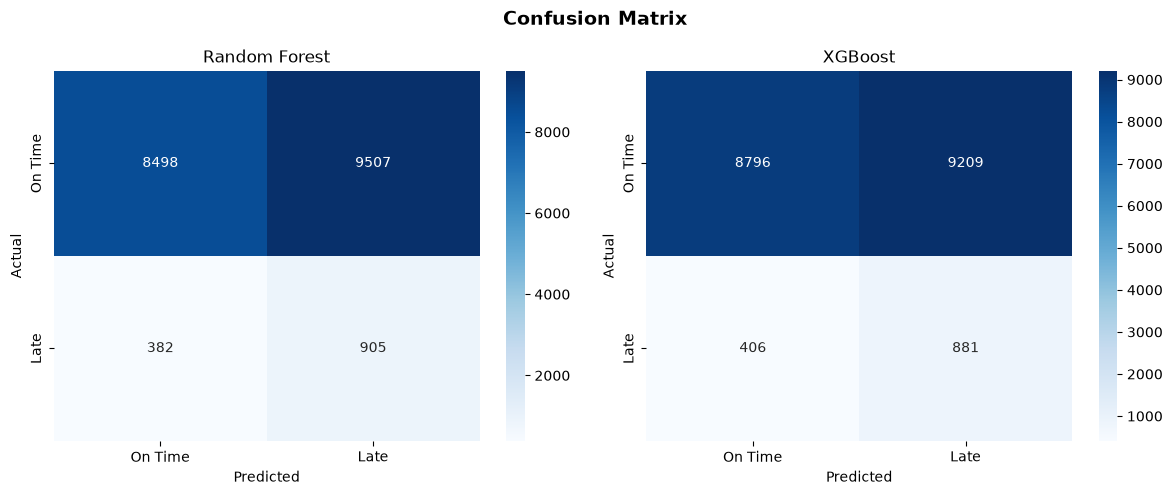

In [66]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Confusion Matrix", fontsize=14, fontweight="bold")

for ax, (name, model) in zip(axes, final_models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test), labels=[0, 1])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", ax=ax,
        xticklabels=["On Time", "Late"],
        yticklabels=["On Time", "Late"],
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

#### Feature Importance

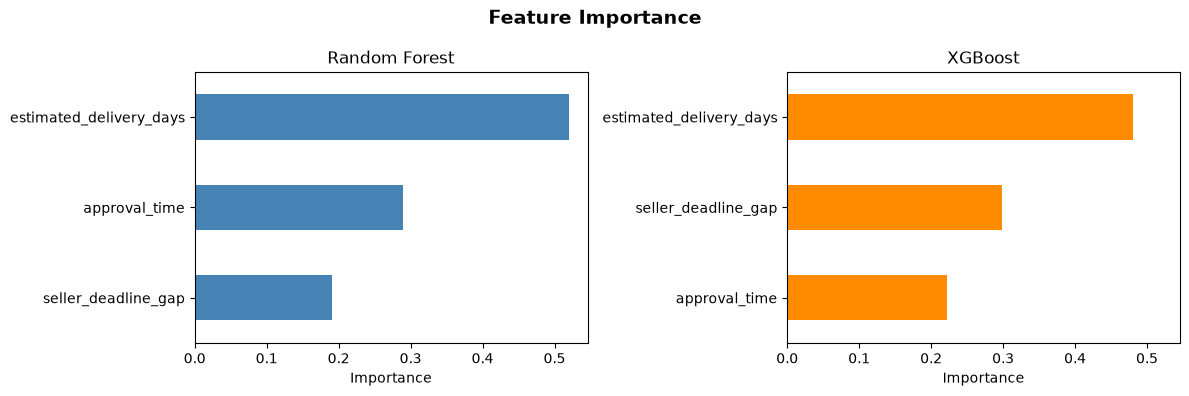

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
fig.suptitle("Feature Importance", fontsize=14, fontweight="bold")

for ax, (name, model), color in zip(axes, final_models.items(), ["steelblue", "darkorange"]):
    importance = pd.Series(model.feature_importances_, index=X_train.columns).sort_values()
    importance.plot(kind="barh", ax=ax, color=color)
    ax.set_title(name)
    ax.set_xlabel("Importance")

plt.tight_layout()
plt.show()